# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [1]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate

In [2]:
filename="../Lab.7/SUSY-small.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", 
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [3]:
import time
import sklearn
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


**My notes (Exercise 2):** Every classifier in scikit-learn has the same interface: create it, call `.fit(X, y)`, then use `.predict`, `.predict_proba` or `.decision_function`. That is what makes it easy to swap classifiers in Exercise 4. The supervised learning list covers linear models, discriminant analysis, SVMs, nearest neighbours, naive Bayes, decision trees, ensembles (random forests, boosting) and neural networks. From the LDA page: LDA fits a Gaussian to each class with one shared covariance matrix, which gives a linear decision boundary in the same direction as the Fisher discriminant I built by hand in Lab 7. QDA gives each class its own covariance matrix, so its boundary is quadratic.

### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [4]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing. (I am using `SUSY-small.csv`, so this is 400k for training and 100k for testing.)

In [5]:
N_Train=400000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


We can train the classifier as follows:

In [6]:
Fisher.fit(X_Train,y_Train)

LinearDiscriminantAnalysis()

We can plot the output, comparing signal and background:

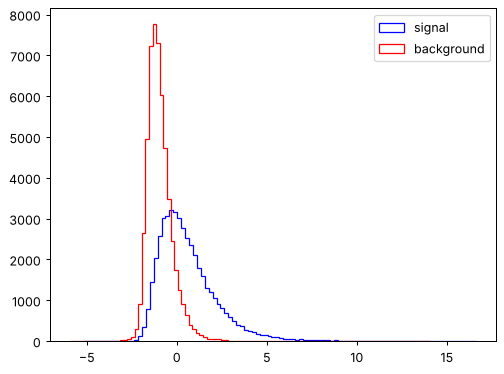

In [7]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

AUC train = 0.8375, test = 0.8384, difference = -0.0009


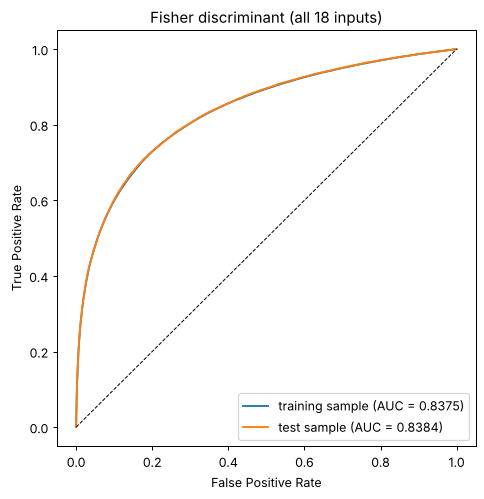

In [8]:
from sklearn.metrics import roc_curve, auc


def plot_roc(ax, y, score, label):
    fpr, tpr, _ = roc_curve(y, score)
    a = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{label} (AUC = {a:.4f})")
    return a


fig, ax = plt.subplots(figsize=(6, 6))
auc_train = plot_roc(ax, y_Train, Fisher.decision_function(X_Train), "training sample")
auc_test = plot_roc(ax, y_Test, Fisher.decision_function(X_Test), "test sample")
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Fisher discriminant (all 18 inputs)")
ax.legend(loc="lower right")
plt.show()
print(f"AUC train = {auc_train:.4f}, test = {auc_test:.4f}, difference = {auc_train - auc_test:+.4f}")

**Answer (3a):** The two ROC curves sit right on top of each other: AUC 0.8375 on the training sample and 0.8384 on the test sample, so I don't see a bias. That makes sense, because LDA only learns one weight per input (plus the class means and covariance) from 400k events, so it can't memorise the training data. The test AUC coming out slightly higher is just a statistical fluctuation.

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

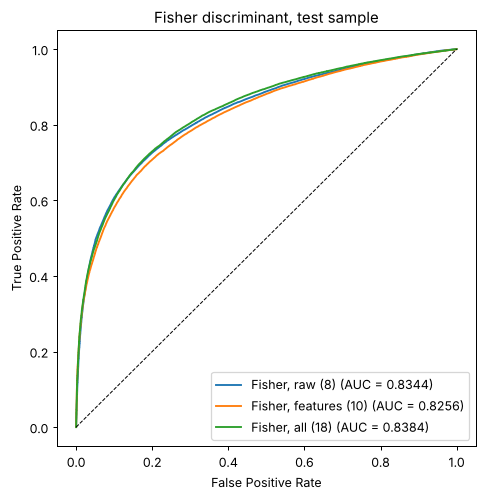

In [9]:
InputSets = {"raw (8)": RawNames, "features (10)": FeatureNames, "all (18)": VarNames[1:]}

fig, ax = plt.subplots(figsize=(6, 6))
FisherAUC = {}
for label, names in InputSets.items():
    model = DA.LinearDiscriminantAnalysis().fit(X_Train[names], y_Train)
    FisherAUC[label] = plot_roc(ax, y_Test, model.decision_function(X_Test[names]), f"Fisher, {label}")
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Fisher discriminant, test sample")
ax.legend(loc="lower right")
plt.show()

**Answer (3b):** On the test sample, Fisher gets AUC 0.834 with only the 8 raw quantities, 0.826 with only the 10 derived features, and 0.838 with all 18. Most of the separation is carried by the raw quantities. A linear combination of them alone beats the derived features, and adding the features on top only gains 0.004. This matches what I found by hand in Lab 7 (0.834 / 0.824 / 0.837).

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

**Part a: my choices.**

1. **Quadratic Discriminant Analysis (QDA).** This is the next step up from LDA: each class gets its own covariance matrix, so the boundary can curve. It trains almost instantly.
2. **Random forest.** It averages many decision trees, each grown on a random subset of the events and inputs, so it can learn non-linear boundaries. I limited the depth and number of trees to keep training time reasonable on my laptop.
3. **Histogram gradient boosting.** It builds trees one after another, each correcting the previous ones, on binned inputs. scikit-learn recommends it for datasets with more than about 10,000 rows.

I skipped the multi-layer perceptron (as the lab says), kernel SVMs (training time grows roughly with the square of the number of events) and k-nearest neighbours (predicting 100k test events is slow).

#### Part b

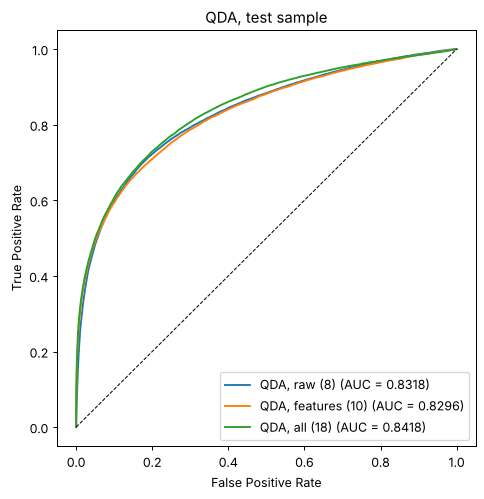

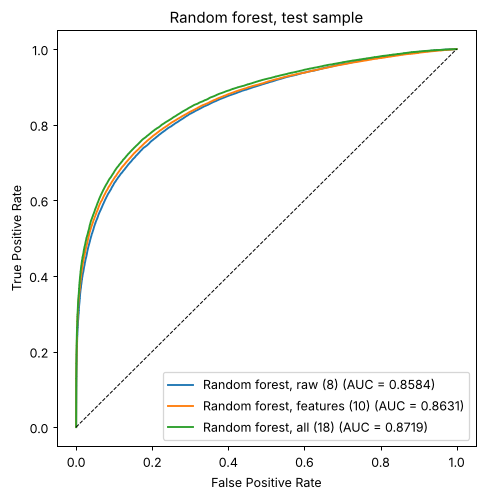

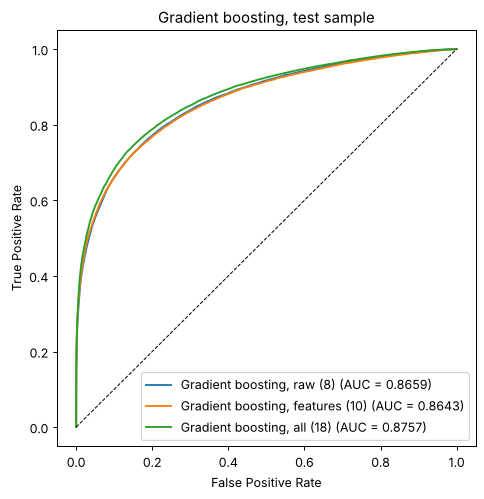

In [10]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier


def classifier_score(model, X):
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def compare_inputs(classifier, name):
    fig, ax = plt.subplots(figsize=(6, 6))
    results = {}
    for label, names in InputSets.items():
        t0 = time.time()
        model = clone(classifier).fit(X_Train[names], y_Train)
        score = classifier_score(model, X_Test[names])
        results[label] = {"score": score, "auc": plot_roc(ax, y_Test, score, f"{name}, {label}"),
                          "seconds": time.time() - t0}
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{name}, test sample")
    ax.legend(loc="lower right")
    plt.show()
    return results


Classifiers = {
    "QDA": DA.QuadraticDiscriminantAnalysis(),
    "Random forest": RandomForestClassifier(n_estimators=50, max_depth=15, min_samples_leaf=20, n_jobs=-1, random_state=0),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=200, random_state=0),
}
Results = {name: compare_inputs(clf, name) for name, clf in Classifiers.items()}

In [11]:
rows = [["Fisher (LDA)"] + [FisherAUC[label] for label in InputSets] + [""]]
for name, res in Results.items():
    rows.append([name] + [res[label]["auc"] for label in InputSets] + [sum(r["seconds"] for r in res.values())])
display(HTML(tabulate.tabulate(rows, headers=["classifier"] + [f"AUC, {label}" for label in InputSets] + ["train + predict time (s)"],
                               tablefmt="html", floatfmt=".4f")))
best_name, best_label = max(((n, l) for n in Results for l in InputSets), key=lambda p: Results[p[0]][p[1]]["auc"])
print("best method:", best_name, "with", best_label, "inputs, AUC =", round(Results[best_name][best_label]["auc"], 4))

best method: Gradient boosting with all (18) inputs, AUC = 0.8757


classifier,"AUC, raw (8)","AUC, features (10)","AUC, all (18)",train + predict time (s)
Fisher (LDA),0.8344,0.8256,0.8384,
QDA,0.8318,0.8296,0.8418,0.9635
Random forest,0.8584,0.8631,0.8719,101.3540
Gradient boosting,0.8659,0.8643,0.8757,12.4837


**Answer (4b):** Gradient boosting with all 18 inputs is the best method (AUC 0.876). The random forest is close (0.872) but about 8 times slower: 101 s against 12 s for the three fits. QDA (0.842) is only a little better than Fisher (0.838). For every method, all 18 inputs beat either subset. The two tree methods do about as well with the raw quantities alone as with the features alone (gradient boosting 0.866 vs 0.864, random forest 0.858 vs 0.863). A flexible model can learn part of what the physicists built into the derived features, but not all of it, since adding the features still helps.

#### Part c

In [12]:
SCENARIOS = {1: (10, 100), 2: (100, 1000), 3: (1000, 10000), 4: (10000, 100000)}
y_test = y_Test.to_numpy()
best_score = Results[best_name][best_label]["score"]


def max_significance(y, score, n=2000):
    ss, sb = np.sort(score[y == 1]), np.sort(score[y == 0])
    thr = np.quantile(score, np.linspace(0.001, 0.999, n))
    es = 1 - np.searchsorted(ss, thr, side="right") / len(ss)
    eb = 1 - np.searchsorted(sb, thr, side="right") / len(sb)
    rows = []
    for sc, (ns, nb) in SCENARIOS.items():
        s, b = es * ns, eb * nb
        z = np.divide(s, np.sqrt(s + b), out=np.zeros_like(s), where=(s + b) > 0)
        i = int(np.argmax(z))
        rows.append({"scenario": sc, "N_S": ns, "N_B": nb, "cut": thr[i], "eps_S": es[i], "eps_B": eb[i],
                     "N'_S": s[i], "N'_B": b[i], "sigma": z[i]})
    return rows


Best = max_significance(y_test, best_score)
display(HTML(tabulate.tabulate([list(r.values()) for r in Best],
                               headers=["scenario", "N_S", "N_B", "cut on output", "ε_S", "ε_B", "N'_S", "N'_B", "σ_S"],
                               tablefmt="html", floatfmt=".4g")))

scenario,N_S,N_B,cut on output,ε_S,ε_B,N'_S,N'_B,σ_S
1,10,100,1.689,0.4539,0.0168,4.539,1.68,1.82
2,100,1000,1.689,0.4539,0.0168,45.39,16.8,5.755
3,1000,10000,1.689,0.4539,0.0168,453.9,168,18.2
4,10000,100000,1.689,0.4539,0.0168,4539,1680,57.55


**Answer (4c):** With gradient boosting on all 18 inputs, and the cut on its output chosen to maximise σ, I get σ_S = 1.82, 5.76, 18.20 and 57.55 for the four scenarios. The best cut is the same in all four (ε_S = 0.454, ε_B = 0.0168), for the same reason as in Lab 7: N_B/N_S = 10 in every scenario, so only the overall scale changes. That is about 19% better than my best Lab 7 result (Fisher: 1.53, 4.85, 15.32, 48.46) and about 21% better than the best single cut on MET (14.99 in scenario 3). One caveat: I picked the cut on the same test sample I measured σ on, so these numbers are very slightly optimistic.

### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

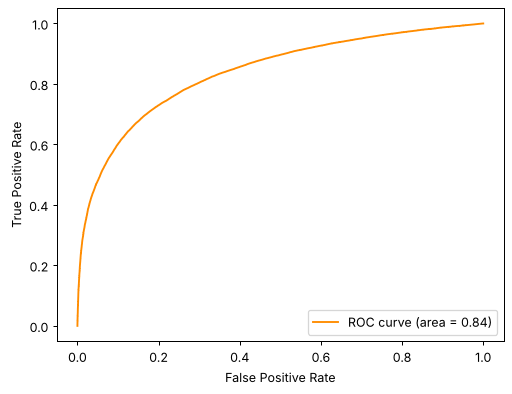

In [13]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


**Part a: my notes.** With TP, FP, TN and FN the counts of true/false positives and negatives:
- **Precision** = TP / (TP + FP): of the events I call signal, the fraction that really are signal.
- **Recall** = TP / (TP + FN): the fraction of real signal I keep. This is the same as the TPR, or signal efficiency.
- **Accuracy** = (TP + TN) / all: the fraction of events classified correctly.
- **F1 score**: the harmonic mean of precision and recall, 2PR / (P + R).

Precision, accuracy and F1 depend on how much signal there is compared with background. TPR, FPR and AUC do not.

#### Part b

In [14]:
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score)

n_sig, n_bkg = (y_test == 1).sum(), (y_test == 0).sum()
auc_best = roc_auc_score(y_test, best_score)
rows = []
for r in Best:
    pred = (best_score > r["cut"]).astype(int)
    w = np.where(y_test == 1, r["N_S"] / n_sig, r["N_B"] / n_bkg)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append([r["scenario"], f"{r['N_S']} / {r['N_B']}", tp / (tp + fn), fp / (fp + tn), auc_best,
                 precision_score(y_test, pred, sample_weight=w), recall_score(y_test, pred, sample_weight=w),
                 f1_score(y_test, pred, sample_weight=w), accuracy_score(y_test, pred, sample_weight=w), r["sigma"]])
pred = (best_score > Best[0]["cut"]).astype(int)
rows.append(["test sample, unweighted", f"{n_sig} / {n_bkg}", recall_score(y_test, pred),
             confusion_matrix(y_test, pred).ravel()[1] / n_bkg, auc_best, precision_score(y_test, pred),
             recall_score(y_test, pred), f1_score(y_test, pred), accuracy_score(y_test, pred), ""])
display(HTML(tabulate.tabulate(rows, headers=["scenario", "N_S / N_B", "TPR", "FPR", "AUC", "precision", "recall",
                                              "F1", "accuracy", "max σ_S"], tablefmt="html", floatfmt=".4f")))

scenario,N_S / N_B,TPR,FPR,AUC,precision,recall,F1,accuracy,max σ_S
1,10 / 100,0.4539,0.0168,0.8757,0.7298,0.4539,0.5597,0.9351,1.8200
2,100 / 1000,0.4539,0.0168,0.8757,0.7298,0.4539,0.5597,0.9351,5.7555
3,1000 / 10000,0.4539,0.0168,0.8757,0.7298,0.4539,0.5597,0.9351,18.2005
4,10000 / 100000,0.4539,0.0168,0.8757,0.7298,0.4539,0.5597,0.9351,57.5549
"test sample, unweighted",45959 / 54041,0.4539,0.0168,0.8757,0.9583,0.4539,0.6160,0.7399,


**Answer (5b):** For each scenario I weighted the test events with `sample_weight` so that signal and background add up to that scenario's N_S and N_B. That way precision, F1 and accuracy describe a 1:10 signal-to-background mix instead of the test sample's roughly 46:54. Since the ratio is 1:10 in all four scenarios and the best cut is the same, every metric except σ is identical across them: TPR 0.454, FPR 0.017, AUC 0.876, precision 0.730, recall 0.454, F1 0.560 and accuracy 0.935. Only σ grows with the number of events. The last row applies the same cut to the unweighted test sample: precision jumps to 0.958 and accuracy drops to 0.740, only because that sample contains much more signal. That is why precision and accuracy can be misleading here, while TPR, FPR and AUC stay the same.